# 04. Evaluation on the test period

This notebook opens the test period **once**, to measure how the product would have done on a year it has never seen.

| | File | Content |
|---|---|---|
| Input | `features_table.parquet` | From `02_features.ipynb`: target, model inputs, Elia benchmark, daylight and split flags |
| Input | `model_settings.json` | From `03_models.ipynb`: the forest's settings, its inputs and its validation scores |
| Output | `test_predictions.parquet` | Every test hour with the measured load factor and the three forecasts, for charts and further analysis |
| Output | `test_scores.json` | The test scores of the three forecasts, for the report |
| Output | `report/figures/test_*.png` | The charts of this notebook, for the report |

**Rules followed**

- **Nothing is tuned here.** The settings and inputs are read from `model_settings.json`, exactly as `03_models.ipynb` chose them on the validation blocks. If a result below looks disappointing, the answer is to report it, not to change a setting and rerun: once a choice is made after seeing the test, the test is no longer a fair exam.
- **The forest is trained once**, on every daylight hour of the training period (15 March 2024 to 25 October 2025), and forecasts the whole test year (26 October 2025 to 25 October 2026) in one go.
- **The two benchmarks are built exactly as in `03_models.ipynb`**: persistence copies the same hour 48 hours earlier, Elia's forecast is its 11:00 day-ahead forecast divided by capacity.

**A note on realism.** A forest trained once and frozen for a full year is a conservative set-up: in production it would be retrained regularly (for example every month) on all the data seen so far. Section 7 shows how much that changes the score, as a separate check. The headline result is the frozen forest, which is the model chosen in `03_models.ipynb`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

TABLE_FILE = Path("features_table.parquet")
SETTINGS_FILE = Path("model_settings.json")
PRED_FILE = Path("test_predictions.parquet")
SCORES_FILE = Path("test_scores.json")
FIG_DIR = Path("report/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

ECMWF_UPGRADE = pd.Timestamp("2026-05-12", tz="UTC")   # new version of the ECMWF forecasting system
PORTFOLIO_MW = 100                                       # example client portfolio for the value section
RETRAIN_MONTHS = 1                                       # retraining interval for the check in section 7

# chart style (same as the other notebooks)
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
BLUE_LIGHT = "#b7d3f6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.edgecolor": AXIS, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.float_format", "{:,.2f}".format)

NAMES = {"persistence": "Persistence (naive rule)", "elia": "Elia day-ahead forecast", "rf": "Random forest"}
COLORS = {"persistence": MUTED, "elia": ORANGE, "rf": BLUE}
MODELS = ["persistence", "elia", "rf"]

def save(fig, name):
    # save a chart for the report, at print resolution
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")

Matplotlib is building the font cache; this may take a moment.


## 1. Load the settings chosen on validation, and both periods

In [2]:
settings = json.loads(SETTINGS_FILE.read_text())
PROVINCE, FEATURES, PARAMS = settings["province"], settings["features"], settings["params"]
print(f"Model: {settings['model']}  {PARAMS}")
print(f"{len(FEATURES)} inputs, chosen in 03_models.ipynb")

full = pd.read_parquet(TABLE_FILE).sort_values("datetime").reset_index(drop=True)
full = full[full["region"] == PROVINCE].reset_index(drop=True)
TEST_START = full.loc[full["split"] == "test", "datetime"].min()

train = full[(full["split"] == "train") & full["is_daylight"]]
test = full[(full["split"] == "test") & full["is_daylight"]].copy()

assert train["datetime"].max() < TEST_START <= test["datetime"].min(), "train and test overlap"
missing_inputs = test[FEATURES].isna().sum().sum()
print(f"\nTraining: {train['datetime'].min():%d %b %Y} to {train['datetime'].max():%d %b %Y}, {len(train):,} daylight hours")
print(f"Test:     {test['datetime'].min():%d %b %Y} to {test['datetime'].max():%d %b %Y}, {len(test):,} daylight hours")
print(f"Missing input values in the test period: {missing_inputs}")

Model: RandomForestRegressor  {'n_estimators': 300, 'max_features': 0.3333333333333333, 'min_samples_leaf': 20, 'random_state': 0}
26 inputs, chosen in 03_models.ipynb



Training: 15 Mar 2024 to 25 Oct 2025, 7,986 daylight hours
Test:     26 Oct 2025 to 25 Oct 2026, 4,685 daylight hours
Missing input values in the test period: 0


## 2. Train the forest once and forecast the test year

In [3]:
forest = RandomForestRegressor(**PARAMS, n_jobs=-1).fit(train[FEATURES], train["lf"])
test["rf"] = np.clip(forest.predict(test[FEATURES]), 0, 1)
print(f"Forest trained on {len(train):,} hours, forecasts made for {len(test):,} test hours")

Forest trained on 7,986 hours, forecasts made for 4,685 test hours


## 3. The two benchmarks

Exactly as in `03_models.ipynb`. For the first two days of the test period, persistence copies the last two days of the training period: those were observed before the forecast was made, so this is not a leak.

In [4]:
lf_by_hour = full.set_index("datetime")["lf"]                   # all hours, night included
test["persistence"] = (test["datetime"] - pd.Timedelta("48h")).map(lf_by_hour)
test["elia"] = test["dayahead11hforecast"] / test["monitoredcapacity"]

missing = test[["persistence", "elia"]].isna().sum()
print(f"Test hours without a persistence value: {missing['persistence']}, without an Elia forecast: {missing['elia']}")
scored = test.dropna(subset=MODELS)
print(f"Hours scored (all three forecasts available): {len(scored):,} of {len(test):,}")

Test hours without a persistence value: 0, without an Elia forecast: 0
Hours scored (all three forecasts available): 4,685 of 4,685


## 4. Test scores

Same measures as in `03_models.ipynb`, in **percentage points of capacity**, on daylight hours:

- **MAE**: average size of the error. The main score.
- **RMSE**: like MAE, but large errors count more.
- **Bias**: average error with its sign. Above zero: too high on average.

In [5]:
def score(actual, forecast):
    # error measures in percentage points of capacity
    err = (np.asarray(forecast) - np.asarray(actual)) * 100
    return {"MAE": np.abs(err).mean(), "RMSE": np.sqrt((err ** 2).mean()), "Bias": err.mean()}

overall = pd.DataFrame({NAMES[m]: score(scored["lf"], scored[m]) for m in MODELS}).T
overall["MAE vs Elia, %"] = (overall["MAE"] / overall.loc[NAMES["elia"], "MAE"] - 1) * 100
overall["MAE vs persistence, %"] = (overall["MAE"] / overall.loc[NAMES["persistence"], "MAE"] - 1) * 100
overall

,MAE,RMSE,Bias,"MAE vs Elia, %","MAE vs persistence, %"
Persistence (naive rule),8.01,12.42,-0.02,159.95,0.00
Elia day-ahead forecast,3.08,4.88,-0.17,0.00,-61.53
Random forest,4.01,6.18,-0.46,30.11,-49.95


### 4.1 Test against validation

If the test MAE is close to the validation MAE, the validation blocks gave an honest picture and the model did not overfit them. A much higher test MAE would mean the validation was optimistic, or that something changed in the test year.

In [6]:
val_scores = settings["validation"]["scores"]
compare = pd.DataFrame({
    "Validation MAE": {NAMES[m]: val_scores[m]["MAE"] for m in MODELS},
    "Test MAE": overall["MAE"],
})
compare["Change"] = compare["Test MAE"] - compare["Validation MAE"]
compare

,Validation MAE,Test MAE,Change
Persistence (naive rule),7.51,8.01,0.50
Elia day-ahead forecast,3.57,3.08,-0.49
Random forest,4.52,4.01,-0.51


## 5. Where the errors are

### 5.1 By quarter of the test year

Errors in points of capacity are naturally larger in the sunny months, because output itself is larger. Compare the three bars inside a quarter, not one quarter with another.

,Persistence (naive rule),Elia day-ahead forecast,Random forest
Oct 2025 to Jan 2026,5.66,2.49,3.40
Jan 2026 to Apr 2026,9.66,3.20,4.28
Apr 2026 to Jul 2026,6.82,3.04,3.80
Jul 2026 to Oct 2026,9.61,3.43,4.44


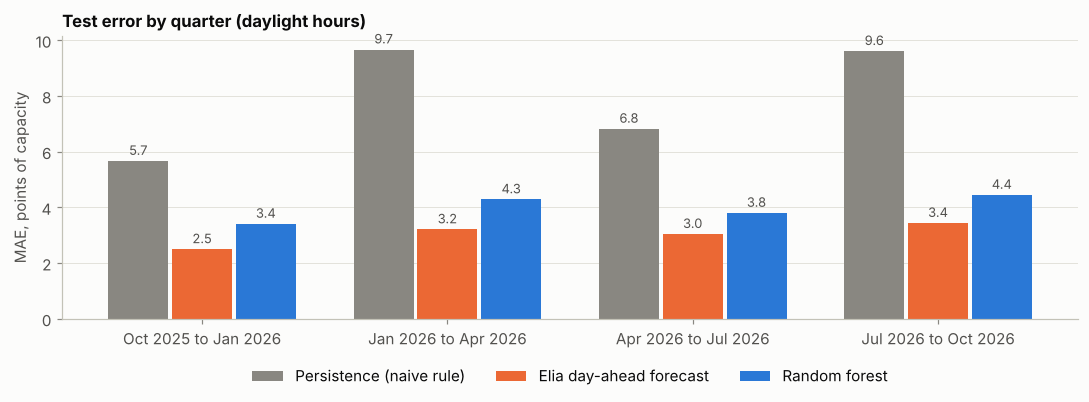

In [7]:
q_edges = [TEST_START + pd.DateOffset(months=3 * k) for k in range(5)]
scored = scored.assign(quarter=pd.cut(scored["datetime"], bins=q_edges, right=False, labels=False) + 1)
per_q = pd.DataFrame({NAMES[m]: scored.groupby("quarter").apply(lambda g: score(g["lf"], g[m])["MAE"], include_groups=False)
                      for m in MODELS})
per_q.index = [f"{q_edges[q - 1]:%b %Y} to {q_edges[q] - pd.Timedelta('1D'):%b %Y}" for q in per_q.index]
display(per_q)

fig, ax = plt.subplots(figsize=(10, 3.8))
x, w = np.arange(len(per_q)), 0.26
for k, m in enumerate(MODELS):
    bars = ax.bar(x + (k - 1) * w, per_q[NAMES[m]], width=w * 0.94, color=COLORS[m], label=NAMES[m])
    ax.bar_label(bars, fmt="%.1f", fontsize=8.5, color=INK2, padding=2)
ax.set_xticks(x, per_q.index); ax.set_ylabel("MAE, points of capacity")
ax.set_title("Test error by quarter (daylight hours)", fontsize=11)
ax.grid(axis="x", visible=False); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); save(fig, "test_mae_by_quarter.png"); plt.show()

### 5.2 By hour and by month

Hours are in Belgian local time.

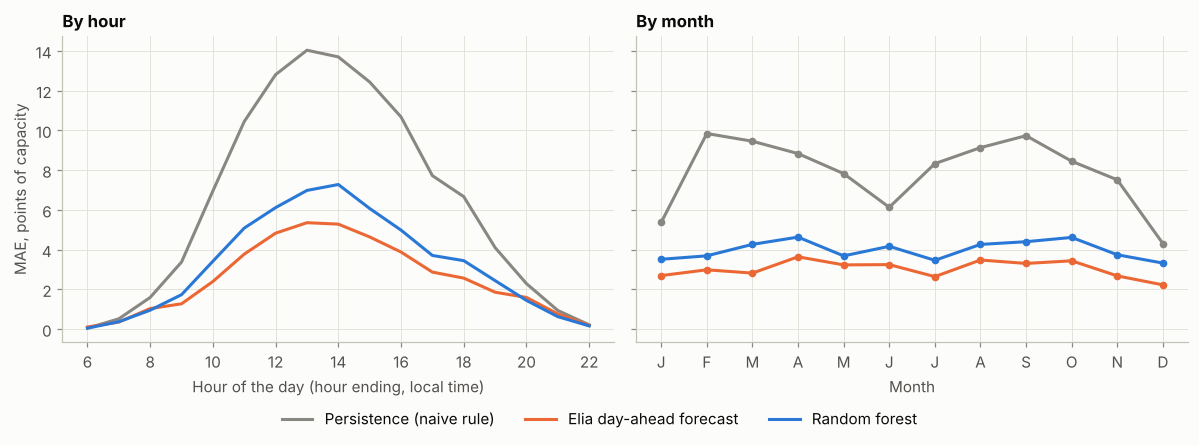

In [8]:
v = scored.copy()
local = v["datetime"].dt.tz_convert("Europe/Brussels")
v["hour"], v["month"] = local.dt.hour, local.dt.month

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for m in MODELS:
    err = (v[m] - v["lf"]).abs() * 100
    by_hour = err.groupby(v["hour"]).mean()
    by_hour = by_hour[v.groupby("hour").size() >= 30]          # skip hours with very few daylight rows
    ax1.plot(by_hour.index, by_hour.values, color=COLORS[m], label=NAMES[m])
    by_month = err.groupby(v["month"]).mean()
    ax2.plot(by_month.index, by_month.values, color=COLORS[m], marker="o", markersize=4)
ax1.set_xlabel("Hour of the day (hour ending, local time)"); ax1.set_ylabel("MAE, points of capacity")
ax1.set_title("By hour", fontsize=11)
ax2.set_xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax2.set_xlabel("Month"); ax2.set_title("By month", fontsize=11)
fig.legend(*ax1.get_legend_handles_labels(), ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.07))
plt.tight_layout(); save(fig, "test_mae_by_hour_month.png"); plt.show()

### 5.3 Before and after the ECMWF upgrade of 12 May 2026

ECMWF moved to a new version of its forecasting system on 12 May 2026, inside the test period. The forest learned how the **old** version's forecasts relate to output. If the new version's forecasts behave differently, the forest could get worse after the upgrade while Elia, who may recalibrate, does not.

The two halves cover different seasons, so their levels cannot be compared directly. What matters is the **gap to Elia** in each half, and the same months of the year before (from the validation blocks) as a reference.

In [9]:
after = scored["datetime"] >= ECMWF_UPGRADE
halves = pd.DataFrame({
    f"Before ({scored.loc[~after, 'datetime'].min():%d %b %Y} to {ECMWF_UPGRADE - pd.Timedelta('1D'):%d %b %Y})":
        {NAMES[m]: score(scored.loc[~after, "lf"], scored.loc[~after, m])["MAE"] for m in MODELS},
    f"After ({ECMWF_UPGRADE:%d %b %Y} to {scored['datetime'].max():%d %b %Y})":
        {NAMES[m]: score(scored.loc[after, "lf"], scored.loc[after, m])["MAE"] for m in MODELS},
}).T
halves["Forest minus Elia"] = halves[NAMES["rf"]] - halves[NAMES["elia"]]

# same calendar window one year earlier, from the validation forecasts of 03_models.ipynb
cv = pd.read_parquet("cv_predictions.parquet")
ref = cv[(cv["datetime"] >= ECMWF_UPGRADE - pd.DateOffset(years=1)) & (cv["datetime"] < TEST_START)]
if len(ref):
    row = {NAMES[m]: score(ref["lf"], ref[m])["MAE"] for m in MODELS}
    row["Forest minus Elia"] = row[NAMES["rf"]] - row[NAMES["elia"]]
    halves.loc[f"Reference: same months a year earlier (validation, {len(ref):,} h)"] = row
halves

,Persistence (naive rule),Elia day-ahead forecast,Random forest,Forest minus Elia
Before (26 Oct 2025 to 11 May 2026),7.98,2.97,4.00,1.03
After (12 May 2026 to 25 Oct 2026),8.05,3.18,4.02,0.84
"Reference: same months a year earlier (validation, 2,497 h)",7.86,3.54,4.65,1.11


### 5.4 The whole test year, and two weeks hour by hour

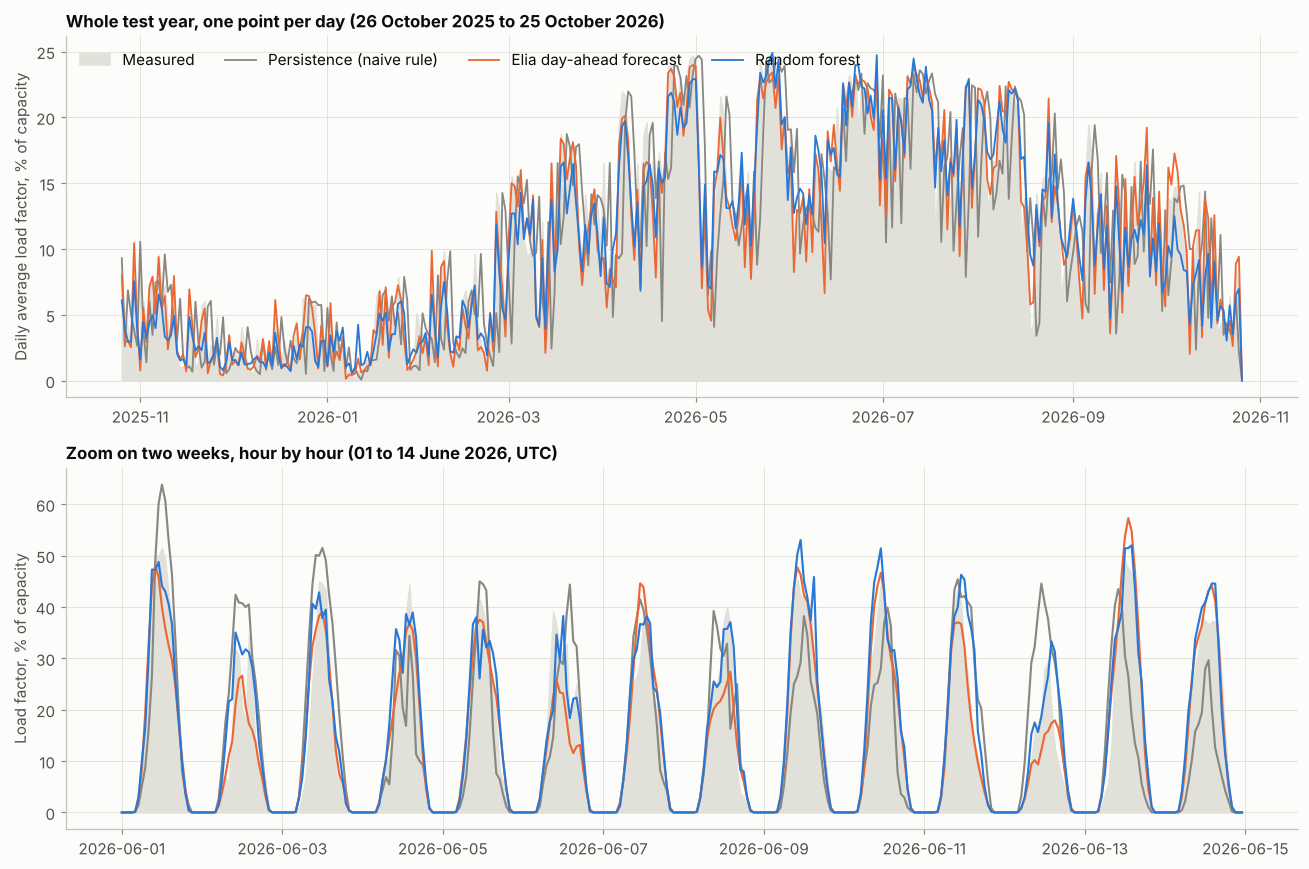

In [10]:
hours = pd.date_range(full["datetime"].min(), full["datetime"].max(), freq="h")
allh = full.set_index("datetime").reindex(hours)
fc = test.set_index("datetime")[MODELS].reindex(hours)
fc = fc.where(allh["is_daylight"].fillna(False).astype(bool), 0.0)       # night forecast as zero

in_test = (hours >= TEST_START)
daily = pd.concat([allh.loc[in_test, ["lf"]], fc.loc[in_test]], axis=1)
daily = daily.groupby(daily.index.tz_convert("Europe/Brussels").date).mean() * 100

zoom_start = pd.Timestamp("2026-06-01", tz="UTC")
zoom = (hours >= zoom_start) & (hours < zoom_start + pd.Timedelta("14D"))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))
ax1.fill_between(pd.to_datetime(daily.index), daily["lf"], color=GRID, label="Measured")
for m in MODELS:
    ax1.plot(pd.to_datetime(daily.index), daily[m], color=COLORS[m], linewidth=1.2, label=NAMES[m])
ax1.set_ylabel("Daily average load factor, % of capacity")
ax1.set_title(f"Whole test year, one point per day ({TEST_START:%d %B %Y} to {hours.max():%d %B %Y})", fontsize=11)
ax1.legend(ncol=4, loc="upper left")

ax2.fill_between(hours[zoom], allh.loc[zoom, "lf"] * 100, color=GRID, label="Measured")
for m in MODELS:
    ax2.plot(hours[zoom], fc.loc[zoom, m] * 100, color=COLORS[m], linewidth=1.4, label=NAMES[m])
ax2.set_ylabel("Load factor, % of capacity")
ax2.set_title(f"Zoom on two weeks, hour by hour ({zoom_start:%d} to {zoom_start + pd.Timedelta('13D'):%d %B %Y}, UTC)", fontsize=11)
plt.tight_layout(); save(fig, "test_forecast_comparison.png"); plt.show()

## 6. What the error means for a client

One point of MAE on a portfolio of 100 MW is 1 MW sold wrongly, on average, in every daylight hour. Over the test year this gives the energy sold at the wrong time, which becomes an imbalance cost. The table shows it for a 100 MW client and for the whole of Antwerp's solar fleet (using its actual capacity hour by hour).

This is energy, not money: the cost in euros needs Elia's imbalance prices for the same hours.

In [11]:
abs_err = {m: (scored[m] - scored["lf"]).abs() for m in MODELS}
value = pd.DataFrame({
    "MAE, points": {NAMES[m]: abs_err[m].mean() * 100 for m in MODELS},
    f"Mis-sold MWh in the test year, {PORTFOLIO_MW} MW client": {NAMES[m]: abs_err[m].sum() * PORTFOLIO_MW for m in MODELS},
    f"Mis-sold MWh in the test year, all of {PROVINCE}": {NAMES[m]: (abs_err[m] * scored["monitoredcapacity"]).sum() for m in MODELS},
})
col = value.columns[1]
saved_vs_persistence = value.loc[NAMES["persistence"], col] - value.loc[NAMES["rf"], col]
gap_to_elia = value.loc[NAMES["rf"], col] - value.loc[NAMES["elia"], col]
display(value.style.format({value.columns[0]: "{:.2f}", value.columns[1]: "{:,.0f}", value.columns[2]: "{:,.0f}"}))
print(f"For a {PORTFOLIO_MW} MW client over the test year ({len(scored):,} daylight hours):")
print(f"  the forest instead of persistence avoids about {saved_vs_persistence:,.0f} MWh of imbalance")
print(f"  the forest is {abs(gap_to_elia):,.0f} MWh {'behind' if gap_to_elia > 0 else 'ahead of'} Elia's forecast")

,"MAE, points","Mis-sold MWh in the test year, 100 MW client","Mis-sold MWh in the test year, all of Antwerp"
Persistence (naive rule),8.01,"37,550","751,116"
Elia day-ahead forecast,3.08,"14,445","289,091"
Random forest,4.01,"18,794","375,933"


For a 100 MW client over the test year (4,685 daylight hours):
  the forest instead of persistence avoids about 18,756 MWh of imbalance
  the forest is 4,349 MWh behind Elia's forecast


## 7. Check: retraining every month

Not used for the headline result. A forest in production would be retrained on the newest data. Here the test year is walked forward one month at a time: each month is forecast by a forest trained on everything observed before that month starts (training period plus the earlier test months). The settings and inputs stay the same, so nothing is tuned on the test.

If the retrained forest is clearly better, the frozen forest is limited by its short history and would improve in use. If not, the extra data adds little.

In [12]:
all_day = full[full["is_daylight"]]
test["rf_retrained"] = np.nan
month_starts = [TEST_START + pd.DateOffset(months=k) for k in range(0, 12, RETRAIN_MONTHS)]
for i, start in enumerate(month_starts):
    end = month_starts[i + 1] if i + 1 < len(month_starts) else test["datetime"].max() + pd.Timedelta("1h")
    learn = all_day[all_day["datetime"] < start]
    rows = (test["datetime"] >= start) & (test["datetime"] < end)
    model = RandomForestRegressor(**PARAMS, n_jobs=-1).fit(learn[FEATURES], learn["lf"])
    test.loc[rows, "rf_retrained"] = np.clip(model.predict(test.loc[rows, FEATURES]), 0, 1)

s = test.dropna(subset=MODELS + ["rf_retrained"])
retrain = pd.DataFrame({
    "Random forest, trained once": score(s["lf"], s["rf"]),
    f"Random forest, retrained every {RETRAIN_MONTHS} month(s)": score(s["lf"], s["rf_retrained"]),
    NAMES["elia"]: score(s["lf"], s["elia"]),
}).T
retrain

,MAE,RMSE,Bias
"Random forest, trained once",4.01,6.18,-0.46
"Random forest, retrained every 1 month(s)",3.89,6.03,-0.29
Elia day-ahead forecast,3.08,4.88,-0.17


## 8. Save

In [13]:
out = test[["datetime", "region", "monitoredcapacity", "lf"] + MODELS + ["rf_retrained"]]
out.to_parquet(PRED_FILE, index=False)

results = {
    "province": PROVINCE,
    "test_period": {"start": str(test["datetime"].min().date()), "end": str(test["datetime"].max().date()),
                    "daylight_hours_scored": int(len(scored))},
    "model": {"name": settings["model"], "params": PARAMS, "n_features": len(FEATURES),
              "trained_on": "all daylight hours of the training period, trained once"},
    "scores": {m: {k: round(float(x), 3) for k, x in score(scored["lf"], scored[m]).items()} for m in MODELS},
    "scores_by_quarter_MAE": {q: {m: round(float(per_q.loc[q, NAMES[m]]), 3) for m in MODELS} for q in per_q.index},
    "rf_retrained_monthly": {k: round(float(x), 3) for k, x in score(s["lf"], s["rf_retrained"]).items()},
    "mis_sold_MWh_per_100MW": {m: round(float(abs_err[m].sum() * PORTFOLIO_MW)) for m in MODELS},
}
SCORES_FILE.write_text(json.dumps(results, indent=2))
print(f"Saved {PRED_FILE}: {len(out):,} test hours")
print(f"Saved {SCORES_FILE}")
print(f"Saved charts in {FIG_DIR}/: " + ", ".join(sorted(p.name for p in FIG_DIR.glob("test_*.png"))))

Saved test_predictions.parquet: 4,685 test hours
Saved test_scores.json
Saved charts in report/figures/: test_forecast_comparison.png, test_mae_by_hour_month.png, test_mae_by_quarter.png


## What goes into the report

- **Section 4.3, test-period table**: the table of section 4 above (MAE, RMSE, Bias, MAE vs Elia).
- **Comment**: section 4.1 (test against validation) and section 5.3 (the ECMWF upgrade).
- **Section 5.3, value for the client**: section 6.
- **Figures**: `report/figures/test_forecast_comparison.png`, `test_mae_by_quarter.png`, `test_mae_by_hour_month.png`.
- **What we would do with more time**: section 7 shows what regular retraining would give.